# Notebook 05: Decision Engine

## AI Revenue Optimization & Conversion Intelligence System for Nattoguard

This notebook combines the outputs from the conversion prediction model and customer segmentation model to create a business decision engine.

The goal is to convert machine learning outputs into practical marketing actions. The decision engine uses:

- Purchase probability
- Customer intent segment
- Behavior segment
- Recommended action

The final output will be used later for LLM-generated emails, SMS messages, ad copy, and chatbot responses.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")

Libraries imported successfully.


In [2]:
CHATBOT_INPUTS_PATH = Path("../outputs/chatbot_inputs")
SLIDE_ASSETS_PATH = Path("../outputs/slide_assets")
FIGURES_PATH = Path("../outputs/figures")
MODEL_RESULTS_PATH = Path("../outputs/model_results")

CHATBOT_INPUTS_PATH.mkdir(parents=True, exist_ok=True)
SLIDE_ASSETS_PATH.mkdir(parents=True, exist_ok=True)
FIGURES_PATH.mkdir(parents=True, exist_ok=True)
MODEL_RESULTS_PATH.mkdir(parents=True, exist_ok=True)

print("Paths prepared successfully.")

Paths prepared successfully.


In [3]:
intent_df = pd.read_csv(CHATBOT_INPUTS_PATH / "customer_intent_recommendations.csv")

print("Intent recommendation data loaded successfully.")
print("Shape:", intent_df.shape)

intent_df.head()

Intent recommendation data loaded successfully.
Shape: (2441, 5)


,session_id,purchase_probability,intent_segment,recommended_action,actual_revenue
0,11640,0.139193,Low Intent,Retarget with awareness ad or product education,0
1,6936,0.134234,Low Intent,Retarget with awareness ad or product education,0
2,7194,0.139599,Low Intent,Retarget with awareness ad or product education,0
3,11263,0.190155,Low Intent,Retarget with awareness ad or product education,0
4,4728,0.000447,Low Intent,Retarget with awareness ad or product education,0


In [4]:
segment_df = pd.read_csv(CHATBOT_INPUTS_PATH / "customer_behavior_segments.csv")

print("Customer behavior segment data loaded successfully.")
print("Shape:", segment_df.shape)

segment_df.head()

Customer behavior segment data loaded successfully.
Shape: (12205, 4)


,session_id,customer_cluster,behavior_segment,Revenue
0,0,0,Low Engagement Browsers,False
1,1,1,Moderate Interest Visitors,False
2,2,0,Low Engagement Browsers,False
3,3,0,Low Engagement Browsers,False
4,4,1,Moderate Interest Visitors,False


In [5]:
decision_df = intent_df.merge(
    segment_df[["session_id", "customer_cluster", "behavior_segment"]],
    on="session_id",
    how="left"
)

print("Decision engine dataset created successfully.")
print("Shape:", decision_df.shape)

decision_df.head()

Decision engine dataset created successfully.
Shape: (2441, 7)


,session_id,purchase_probability,intent_segment,recommended_action,actual_revenue,customer_cluster,behavior_segment
0,11640,0.139193,Low Intent,Retarget with awareness ad or product education,0,1,Moderate Interest Visitors
1,6936,0.134234,Low Intent,Retarget with awareness ad or product education,0,1,Moderate Interest Visitors
2,7194,0.139599,Low Intent,Retarget with awareness ad or product education,0,2,High-Value Intent Users
3,11263,0.190155,Low Intent,Retarget with awareness ad or product education,0,1,Moderate Interest Visitors
4,4728,0.000447,Low Intent,Retarget with awareness ad or product education,0,0,Low Engagement Browsers


In [6]:
decision_df.isnull().sum()

session_id              0
purchase_probability    0
intent_segment          0
recommended_action      0
actual_revenue          0
customer_cluster        0
behavior_segment        0
dtype: int64

In [7]:
print("Missing behavior segments:", decision_df["behavior_segment"].isnull().sum())

Missing behavior segments: 0


In [8]:
def assign_priority(row):
    intent = row["intent_segment"]
    behavior = row["behavior_segment"]
    
    if intent == "High Intent" and behavior == "High-Value Intent Users":
        return "Priority 1 - Immediate Conversion"
    
    elif intent == "High Intent":
        return "Priority 2 - Strong Conversion Opportunity"
    
    elif intent == "Medium Intent" and behavior == "High-Value Intent Users":
        return "Priority 2 - Strong Conversion Opportunity"
    
    elif intent == "Medium Intent":
        return "Priority 3 - Education Needed"
    
    else:
        return "Priority 4 - Awareness / Retargeting"

decision_df["decision_priority"] = decision_df.apply(assign_priority, axis=1)

decision_df[[
    "purchase_probability",
    "intent_segment",
    "behavior_segment",
    "decision_priority"
]].head(10)

,purchase_probability,intent_segment,behavior_segment,decision_priority
0,0.139193,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting
1,0.134234,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting
2,0.139599,Low Intent,High-Value Intent Users,Priority 4 - Awareness / Retargeting
3,0.190155,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting
4,0.000447,Low Intent,Low Engagement Browsers,Priority 4 - Awareness / Retargeting
5,0.915141,High Intent,High-Value Intent Users,Priority 1 - Immediate Conversion
6,0.029458,Low Intent,Low Engagement Browsers,Priority 4 - Awareness / Retargeting
7,0.212766,Low Intent,High-Value Intent Users,Priority 4 - Awareness / Retargeting
8,0.350532,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting
9,0.036681,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting


In [9]:
def assign_campaign_type(priority):
    if priority == "Priority 1 - Immediate Conversion":
        return "Conversion Campaign"
    elif priority == "Priority 2 - Strong Conversion Opportunity":
        return "Retargeting + Offer Campaign"
    elif priority == "Priority 3 - Education Needed":
        return "Educational Nurture Campaign"
    else:
        return "Awareness Campaign"

decision_df["campaign_type"] = decision_df["decision_priority"].apply(assign_campaign_type)

decision_df[[
    "intent_segment",
    "behavior_segment",
    "decision_priority",
    "campaign_type"
]].head(10)

,intent_segment,behavior_segment,decision_priority,campaign_type
0,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting,Awareness Campaign
1,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting,Awareness Campaign
2,Low Intent,High-Value Intent Users,Priority 4 - Awareness / Retargeting,Awareness Campaign
3,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting,Awareness Campaign
4,Low Intent,Low Engagement Browsers,Priority 4 - Awareness / Retargeting,Awareness Campaign
5,High Intent,High-Value Intent Users,Priority 1 - Immediate Conversion,Conversion Campaign
6,Low Intent,Low Engagement Browsers,Priority 4 - Awareness / Retargeting,Awareness Campaign
7,Low Intent,High-Value Intent Users,Priority 4 - Awareness / Retargeting,Awareness Campaign
8,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting,Awareness Campaign
9,Low Intent,Moderate Interest Visitors,Priority 4 - Awareness / Retargeting,Awareness Campaign


In [10]:
def assign_marketing_channel(row):
    priority = row["decision_priority"]
    behavior = row["behavior_segment"]
    
    if priority == "Priority 1 - Immediate Conversion":
        return "Email + SMS"
    
    elif priority == "Priority 2 - Strong Conversion Opportunity":
        return "Email + Meta Retargeting Ads"
    
    elif priority == "Priority 3 - Education Needed":
        return "Email Newsletter / Product Education"
    
    else:
        return "Meta Awareness Ads / Blog Content"

decision_df["suggested_channel"] = decision_df.apply(assign_marketing_channel, axis=1)

decision_df[[
    "decision_priority",
    "campaign_type",
    "suggested_channel"
]].head(10)

,decision_priority,campaign_type,suggested_channel
0,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
1,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
2,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
3,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
4,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
5,Priority 1 - Immediate Conversion,Conversion Campaign,Email + SMS
6,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
7,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
8,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content
9,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content


In [11]:
def assign_chatbot_route(row):
    priority = row["decision_priority"]
    
    if priority == "Priority 1 - Immediate Conversion":
        return "checkout_support"
    
    elif priority == "Priority 2 - Strong Conversion Opportunity":
        return "product_benefits"
    
    elif priority == "Priority 3 - Education Needed":
        return "digestive_health_education"
    
    else:
        return "general_awareness"

decision_df["chatbot_route"] = decision_df.apply(assign_chatbot_route, axis=1)

decision_df[[
    "intent_segment",
    "behavior_segment",
    "chatbot_route"
]].head(10)

,intent_segment,behavior_segment,chatbot_route
0,Low Intent,Moderate Interest Visitors,general_awareness
1,Low Intent,Moderate Interest Visitors,general_awareness
2,Low Intent,High-Value Intent Users,general_awareness
3,Low Intent,Moderate Interest Visitors,general_awareness
4,Low Intent,Low Engagement Browsers,general_awareness
5,High Intent,High-Value Intent Users,checkout_support
6,Low Intent,Low Engagement Browsers,general_awareness
7,Low Intent,High-Value Intent Users,general_awareness
8,Low Intent,Moderate Interest Visitors,general_awareness
9,Low Intent,Moderate Interest Visitors,general_awareness


In [12]:
decision_summary = decision_df.groupby([
    "decision_priority",
    "campaign_type",
    "suggested_channel"
]).size().reset_index(name="session_count")

decision_summary

,decision_priority,campaign_type,suggested_channel,session_count
0,Priority 1 - Immediate Conversion,Conversion Campaign,Email + SMS,97
1,Priority 2 - Strong Conversion Opportunity,Retargeting + Offer Campaign,Email + Meta Retargeting Ads,388
2,Priority 3 - Education Needed,Educational Nurture Campaign,Email Newsletter / Product Education,183
3,Priority 4 - Awareness / Retargeting,Awareness Campaign,Meta Awareness Ads / Blog Content,1773


In [13]:
decision_summary.to_csv(
    SLIDE_ASSETS_PATH / "decision_engine_summary.csv",
    index=False
)

print("Decision engine summary saved successfully.")

Decision engine summary saved successfully.


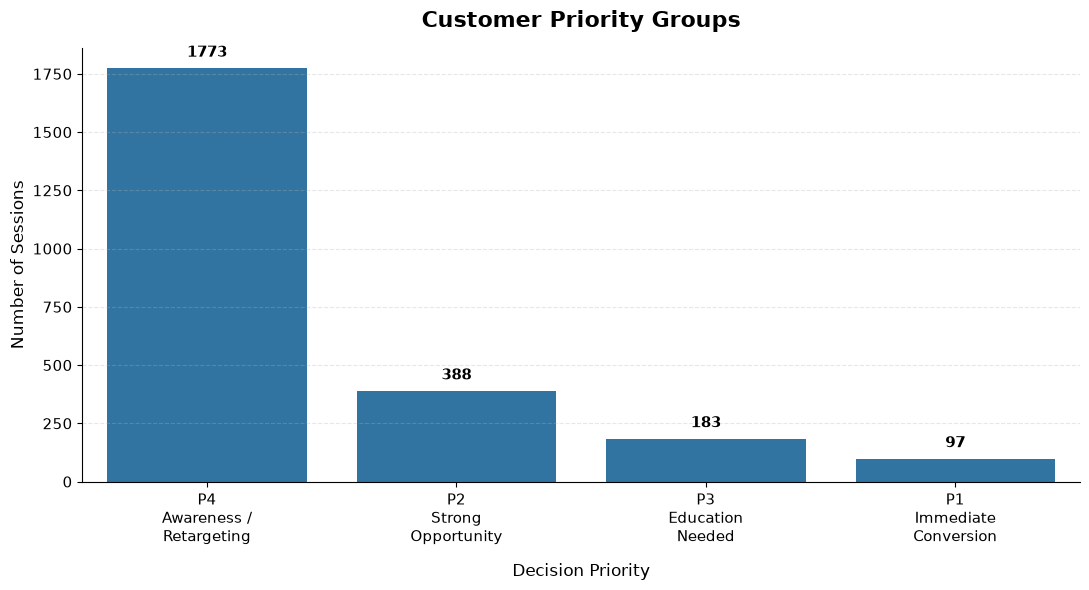

In [19]:
# Create priority distribution table
priority_distribution = decision_df["decision_priority"].value_counts().reset_index()
priority_distribution.columns = ["Decision Priority", "Count"]

priority_label_map = {
    "Priority 1 - Immediate Conversion": "P1\nImmediate\nConversion",
    "Priority 2 - Strong Conversion Opportunity": "P2\nStrong\nOpportunity",
    "Priority 3 - Education Needed": "P3\nEducation\nNeeded",
    "Priority 4 - Awareness / Retargeting": "P4\nAwareness /\nRetargeting"
}

priority_distribution["Decision Priority"] = (
    priority_distribution["Decision Priority"].replace(priority_label_map)
)

priority_order = [
    "P4\nAwareness /\nRetargeting",
    "P2\nStrong\nOpportunity",
    "P3\nEducation\nNeeded",
    "P1\nImmediate\nConversion"
]

priority_distribution["Decision Priority"] = pd.Categorical(
    priority_distribution["Decision Priority"],
    categories=priority_order,
    ordered=True
)

priority_distribution = priority_distribution.sort_values("Decision Priority")

# Plot
plt.figure(figsize=(11, 6))
ax = sns.barplot(
    data=priority_distribution,
    x="Decision Priority",
    y="Count"
)

for i, value in enumerate(priority_distribution["Count"]):
    ax.text(
        i,
        value + 35,
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.title("Customer Priority Groups", fontsize=16, fontweight="bold", pad=15)
plt.xlabel("Decision Priority", fontsize=12, labelpad=12)
plt.ylabel("Number of Sessions", fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

sns.despine()

plt.grid(axis="y", linestyle="--", alpha=0.3)

# Prevent labels from being cut off
plt.tight_layout()

# Save polished version
plt.savefig(
    FIGURES_PATH / "decision_priority_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

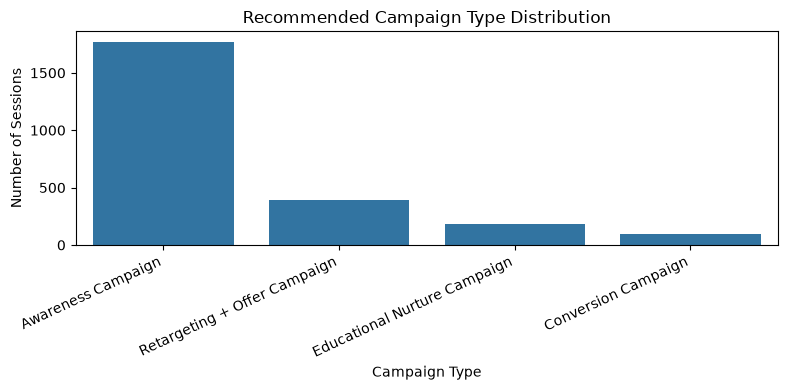

In [16]:
campaign_distribution = decision_df["campaign_type"].value_counts().reset_index()
campaign_distribution.columns = ["Campaign Type", "Count"]

plt.figure(figsize=(8, 4))
sns.barplot(
    data=campaign_distribution,
    x="Campaign Type",
    y="Count"
)
plt.title("Recommended Campaign Type Distribution")
plt.xlabel("Campaign Type")
plt.ylabel("Number of Sessions")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_PATH / "campaign_type_distribution.png", dpi=300)
plt.show()

In [17]:
decision_df.to_csv(
    MODEL_RESULTS_PATH / "decision_engine_full_output.csv",
    index=False
)

decision_df.to_csv(
    CHATBOT_INPUTS_PATH / "decision_engine_chatbot_input.csv",
    index=False
)

print("Decision engine output saved successfully.")

Decision engine output saved successfully.


## Decision Engine Conclusion

In this notebook, the outputs from the conversion prediction model and customer segmentation model were combined to create a business decision engine.

The decision engine uses purchase probability, intent segment, and behavior segment to assign:

- Decision priority
- Campaign type
- Suggested marketing channel
- LLM message goal
- Chatbot route

This step converts machine learning outputs into practical business actions. The final decision engine output will be used in the next stage to generate personalized marketing messages and chatbot responses.